In [1]:
#导入库
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from PyQt6.QtOpenGL import QOpenGLFunctions_4_1_Core
from matplotlib import rcParams
from seaborn import scatterplot

rcParams['font.sans-serif'] = ['Microsoft YaHei']

In [2]:
#读取数据
df = pd.read_csv('data/电商数据_手机3C_模拟2000条.csv')

In [3]:
#去除无用列
df.drop(columns = ['抓取时间','商品链接'], inplace = True)

In [4]:
#增加‘销量’列
df['销量'] = df['评价数']

In [5]:
#数据预览
df.head(3)

,商品ID,商品标题,品牌,类目,现价(元),原价(元),折扣率(%),评价数,好评率,店铺名称,是否自营,销量
0,68370720873,Apple 旗舰 智能手表 标准版,Apple,智能手表,2449,2779,11.9,143,0.978,Apple官方旗舰店,第三方,143
1,71076327392,荣耀 高速 智能手机 12GB+256GB,荣耀,智能手机,9269,12338,24.9,6998,0.983,某某数码专营店,第三方,6998
2,19028924397,三星 超清 显示器 高配版,三星,显示器,3209,4441,27.7,914,0.979,三星数码专营店,第三方,914


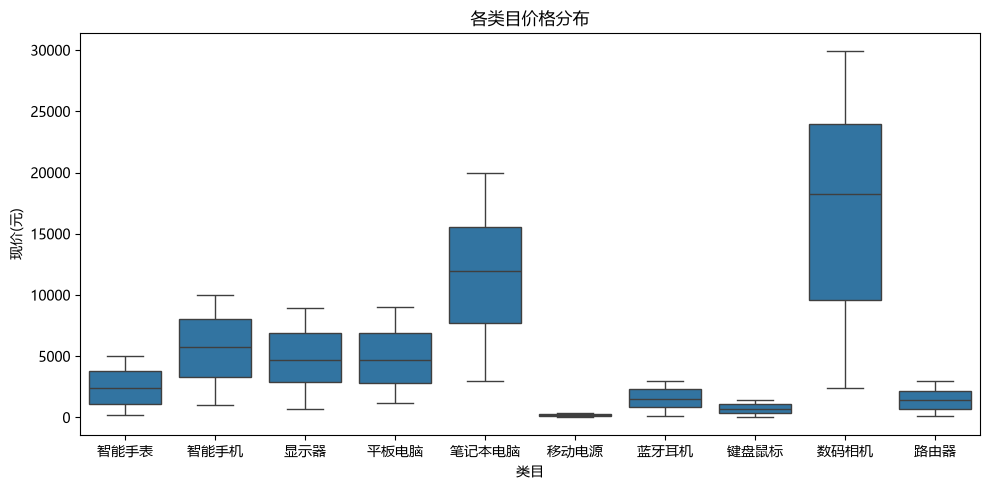

,现价(元)
品牌,
AOC,5277.235294
Anker,217.416667
Apple,5482.030303
Beats,1421.631579
Bose,1391.307692
LG,4849.357143
OPPO,3840.585366
Sony,8605.341463
TP-LINK,1189.740741


In [6]:
#价格分布、品牌价格定位
plt.figure(figsize=(10,5))
sns.boxplot(data = df, x = '类目', y = '现价(元)')
plt.title('各类目价格分布')
plt.tight_layout()
plt.show()

brand_mean_price = df.groupby('品牌')[['现价(元)']].mean()
brand_mean_price

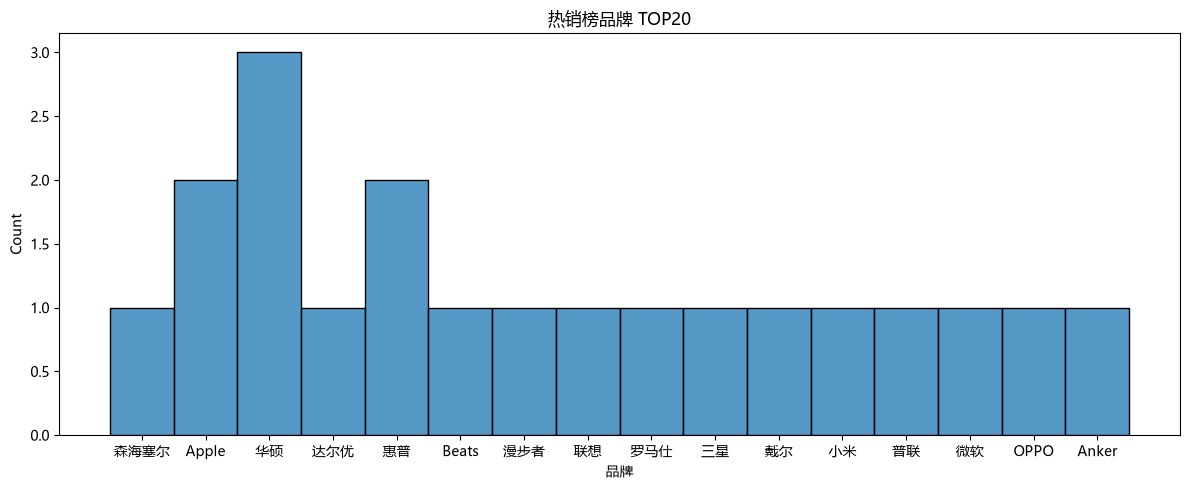

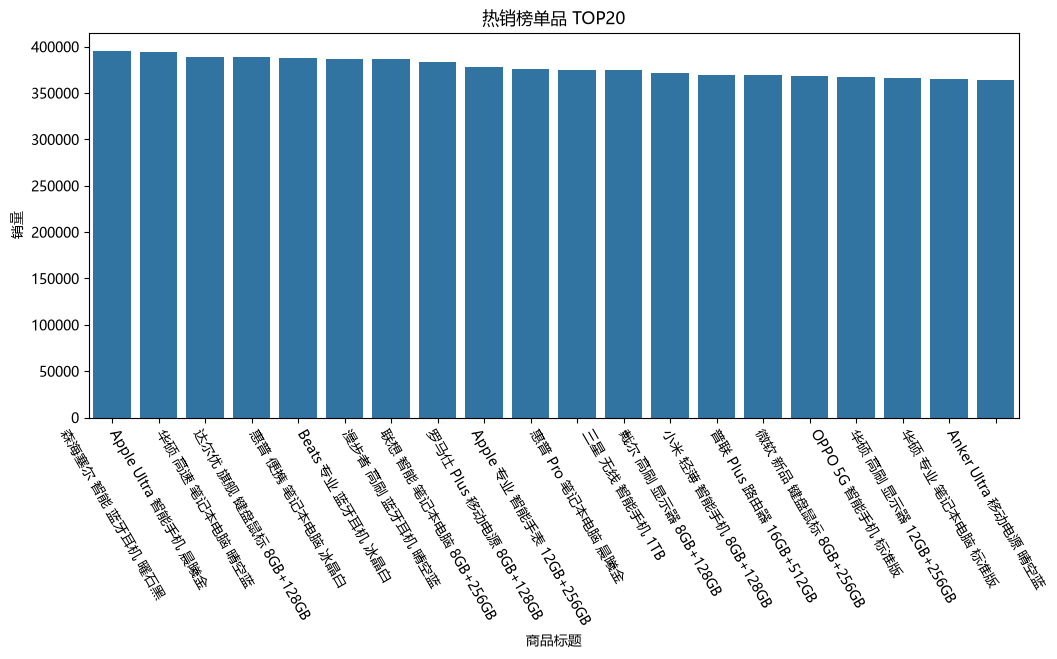

In [7]:
#热销榜 TOP20
hot_sell_top20 = df.sort_values(by = '销量', ascending = False).iloc[1:-1].reset_index(drop = True).head(20)
plt.figure(figsize=(12,5))
sns.histplot(data = hot_sell_top20, x = '品牌' )
plt.title('热销榜品牌 TOP20')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
sns.barplot(data = hot_sell_top20, x = '商品标题',y = '销量')
plt.title('热销榜单品 TOP20')
plt.xticks(rotation = -60)
plt.show()

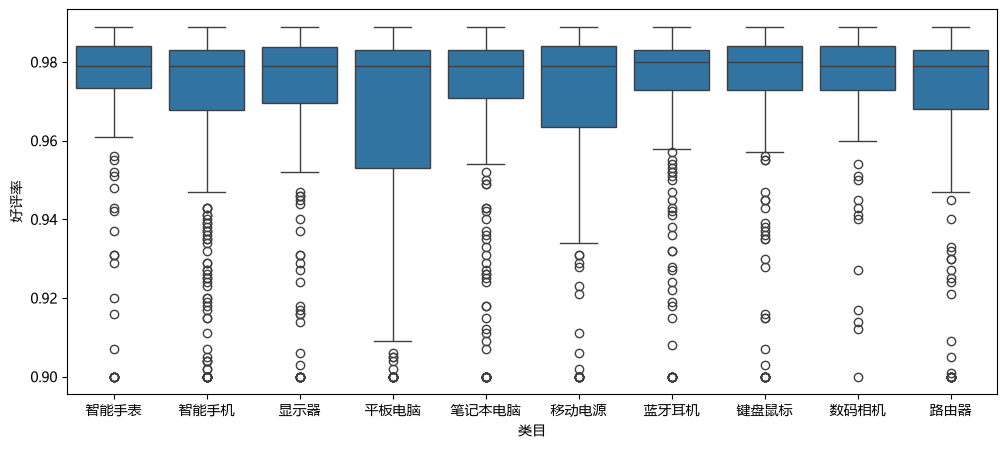

In [8]:
#好评率分布
plt.figure(figsize=(12,5))
sns.boxplot(data = df, x = '类目', y = '好评率')
plt.tight_layout
plt.show()

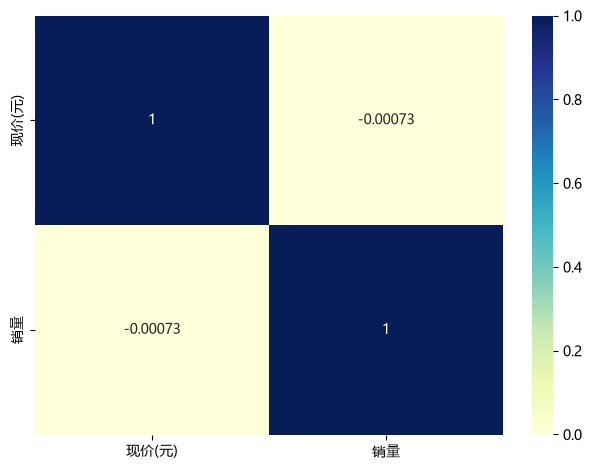

In [9]:
#价格×销量相关性
Q1 = df['销量'].quantile(0.25)
Q3 = df['销量'].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR
price_sales =df[(df['销量']>low) & (df['销量']<high)]
price_sales_cor = price_sales[['现价(元)', '销量']].corr()
sns.heatmap(pd.DataFrame(price_sales_cor), annot=True, cmap = 'YlGnBu')
plt.tight_layout()
plt.show()


In [11]:
"""
1. 数据交付

平台京东、类目「手机/3C数码」，去重后 ≥ 2000 条，覆盖多品牌、多子类目、多价格带、自营+第三方。
必需字段：商品ID、标题、品牌、类目、现价、原价、折扣率、评价数、好评率、店铺、是否自营、链接、抓取时间。
CSV（UTF-8 带 BOM）+ 爬虫脚本 + 日志，可复现、可审计。
2. 数据质量

按商品ID去重；核心字段（现价/评价数/品牌）缺失率 ≤ 2%。
价格异常（≤0、超类目上限）剔除或标记；「超高评价+满分好评」标记为可疑刷单，不计入口碑结论。
口径统一：销量用评价数作代理（报告须注明）；「万+」转数值；品牌归一化（Apple/苹果合并）。
3. 分析指标（5 个维度，缺一不可）

价格：价格分布、价格带结构、折扣率（识别真降价 vs 虚标原价）。
品牌：份额（商品数/评价数两口径）、TOP10、集中度 CR4/CR10、品牌价格定位。
销量口碑：热销榜 TOP20、好评率分布、「口碑爆款 vs 翻车爆款」、价格×销量相关性。
店铺：自营 vs 第三方在价格/销量/好评率上的差异。
类目：各子类目商品数/均价/总评价量，识别蓝海红海。
"""

'\n1. 数据交付\n\n平台京东、类目「手机/3C数码」，去重后 ≥ 2000 条，覆盖多品牌、多子类目、多价格带、自营+第三方。\n必需字段：商品ID、标题、品牌、类目、现价、原价、折扣率、评价数、好评率、店铺、是否自营、链接、抓取时间。\nCSV（UTF-8 带 BOM）+ 爬虫脚本 + 日志，可复现、可审计。\n2. 数据质量\n\n按商品ID去重；核心字段（现价/评价数/品牌）缺失率 ≤ 2%。\n价格异常（≤0、超类目上限）剔除或标记；「超高评价+满分好评」标记为可疑刷单，不计入口碑结论。\n口径统一：销量用评价数作代理（报告须注明）；「万+」转数值；品牌归一化（Apple/苹果合并）。\n3. 分析指标（5 个维度，缺一不可）\n\n价格：价格分布、价格带结构、折扣率（识别真降价 vs 虚标原价）。\n品牌：份额（商品数/评价数两口径）、TOP10、集中度 CR4/CR10、品牌价格定位。\n销量口碑：热销榜 TOP20、好评率分布、「口碑爆款 vs 翻车爆款」、价格×销量相关性。\n店铺：自营 vs 第三方在价格/销量/好评率上的差异。\n类目：各子类目商品数/均价/总评价量，识别蓝海红海。\n'